# 5 — Visualización orientada a preguntas

Un gráfico no es el objetivo: es evidencia para responder una pregunta. En cada ejercicio primero escribí qué querés averiguar, luego construí la agregación y finalmente redactá una conclusión de dos o tres oraciones.

Este notebook se ejecuta manualmente **después** de que el Job termina correctamente; no forma parte del pipeline.

In [0]:
dbutils.widgets.text("student_id", "alumno01", "01 - Identificador")
dbutils.widgets.dropdown("scale", "small", ["test", "small", "demo"], "02 - Escala")

In [0]:
%run ../common/config

In [0]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

catalog = spark.sql("SELECT current_catalog()").first()[0]
config = CourseConfig(catalog, dbutils.widgets.get("student_id"), dbutils.widgets.get("scale"))
daily = qualified_table(config, "gold_daily_sales")
risk = qualified_table(config, "gold_customer_risk")
batch = qualified_table(config, "gold_batch_summary")
for table in [daily, risk, batch]:
    assert spark.catalog.tableExists(table), f"Falta {table}. Ejecutá primero el Job completo."

## Ejemplo resuelto

**Pregunta:** ¿Qué categoría concentra el mayor monto vendido?

La agregación se hace con Spark. Sólo el resultado pequeño se convierte a Pandas para dibujarlo. Un gráfico de barras ordenado permite comparar categorías; un gráfico de torta haría más difícil comparar valores cercanos.

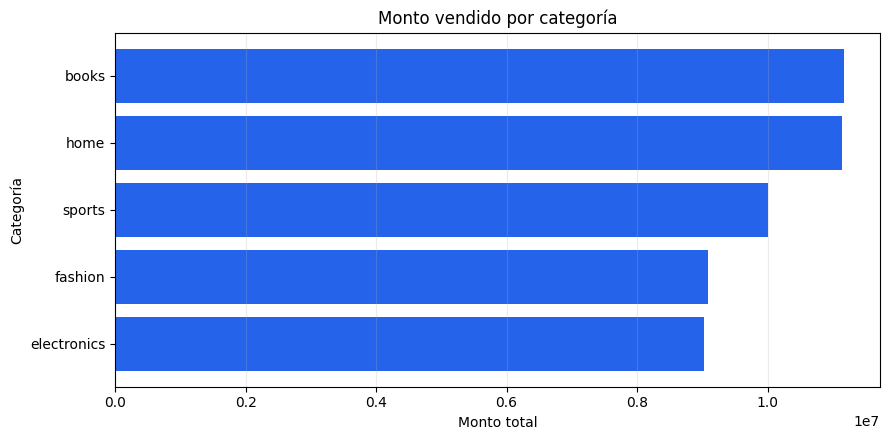

Respuesta: books es la categoría con mayor monto vendido (11,165,281.86).


In [0]:
category_sales = (spark.table(daily)
    .groupBy("category")
    .agg(F.sum("total_amount").alias("total_amount"))
    .orderBy(F.desc("total_amount")))

plot_data = category_sales.toPandas().sort_values("total_amount")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(plot_data["category"], plot_data["total_amount"], color="#2563eb")
ax.set_title("Monto vendido por categoría")
ax.set_xlabel("Monto total")
ax.set_ylabel("Categoría")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

leader = category_sales.first()
print(f"Respuesta: {leader.category} es la categoría con mayor monto vendido ({leader.total_amount:,.2f}).")

## Consigna 1 — Evolución temporal

**Pregunta:** ¿Qué día tuvo el mayor monto vendido y ese día también fue el de mayor cantidad de transacciones?

Construí una visualización temporal que permita comparar ambas métricas sin ocultar sus unidades. Explicá si los dos máximos coinciden y qué implica que coincidan —o no— sobre el ticket promedio. Fuente sugerida: `gold_daily_sales`.

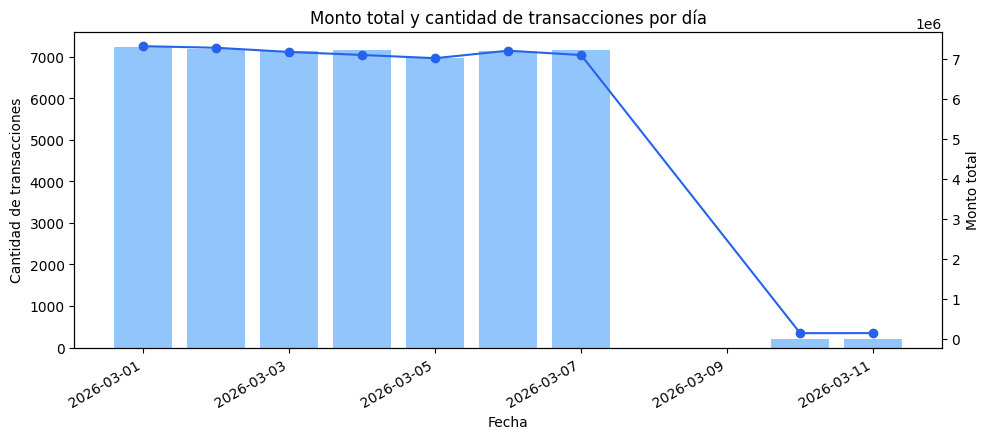

In [0]:
daily_data = (spark.table(daily)
    .groupBy("sale_date")
    .agg(
        F.sum("total_amount").alias("total_amount"),
        F.sum("transaction_count").alias("transaction_count")
    )
    .orderBy("sale_date"))

plot_data = daily_data.toPandas()

fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.bar(plot_data["sale_date"], plot_data["transaction_count"], color="#93c5fd", label="Transacciones")
ax1.set_ylabel("Cantidad de transacciones")
ax1.set_xlabel("Fecha")

ax2 = ax1.twinx()
ax2.plot(plot_data["sale_date"], plot_data["total_amount"], color="#2563eb", marker="o", label="Monto total")
ax2.set_ylabel("Monto total")

ax1.set_title("Monto total y cantidad de transacciones por día")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

El 2026-03-01 tuvo el mayor monto total (7310840.77) y también la mayor cantidad de transacciones (7236), así que ambos máximos coinciden en el mismo día. Eso tiene sentido: al ser el día con más volumen de transacciones, es también el que más monto acumula, sin que eso implique un ticket promedio distinto al resto.

## Consigna 2 — Canal y fraude

**Pregunta:** ¿Qué canal de pago presenta la mayor tasa de fraude? ¿La conclusión se sostiene al considerar el número de transacciones de cada canal?

Mostrá tasa y volumen de manera legible. No compares sólo cantidades de fraude: calculá el denominador correcto. Fuente sugerida: `gold_daily_sales`.

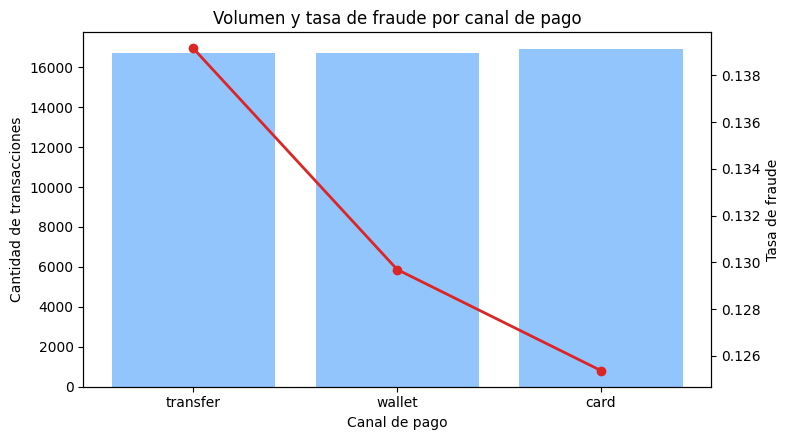

+---------------+------------------+-----------------+-------------------+
|payment_channel|fraud_transactions|transaction_count|         fraud_rate|
+---------------+------------------+-----------------+-------------------+
|       transfer|              2327|            16723| 0.1391496741015368|
|         wallet|              2169|            16724| 0.1296938531451806|
|           card|              2119|            16902|0.12536977872441132|
+---------------+------------------+-----------------+-------------------+



In [0]:
channel_data = (spark.table(daily)
    .groupBy("payment_channel")
    .agg(
        F.sum("fraud_transactions").alias("fraud_transactions"),
        F.sum("transaction_count").alias("transaction_count")
    )
    .withColumn("fraud_rate", F.col("fraud_transactions") / F.col("transaction_count"))
    .orderBy(F.desc("fraud_rate")))

plot_data = channel_data.toPandas()

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.bar(plot_data["payment_channel"], plot_data["transaction_count"], color="#93c5fd", label="Transacciones")
ax1.set_ylabel("Cantidad de transacciones")
ax1.set_xlabel("Canal de pago")

ax2 = ax1.twinx()
ax2.plot(plot_data["payment_channel"], plot_data["fraud_rate"], color="#dc2626", marker="o", linewidth=2, label="Tasa de fraude")
ax2.set_ylabel("Tasa de fraude")

ax1.set_title("Volumen y tasa de fraude por canal de pago")
fig.tight_layout()
plt.show()

channel_data.show()

`transfer` tiene la tasa global de fraude más alta (13.9%), seguido de `wallet` (13.0%) y `card` (12.5%). La conclusión se sostiene al considerar la cantidad: los tres canales tienen una cantidad de transacciones muy similar (~16700-16900), así que la diferencia en tasa de fraude no se explica por un canal con pocos datos distorsionando el resultado — es una diferencia real entre canales con volúmenes comparables.

## Consigna 3 — Concentración geográfica y de producto

**Pregunta:** ¿Qué combinación de país y categoría genera el mayor monto? ¿Existe una categoría dominante en todos los países o cambia según el mercado?

Elegí una visualización que permita comparar simultáneamente países y categorías. Justificá brevemente por qué ese tipo de gráfico es adecuado. Fuente sugerida: `gold_daily_sales`.

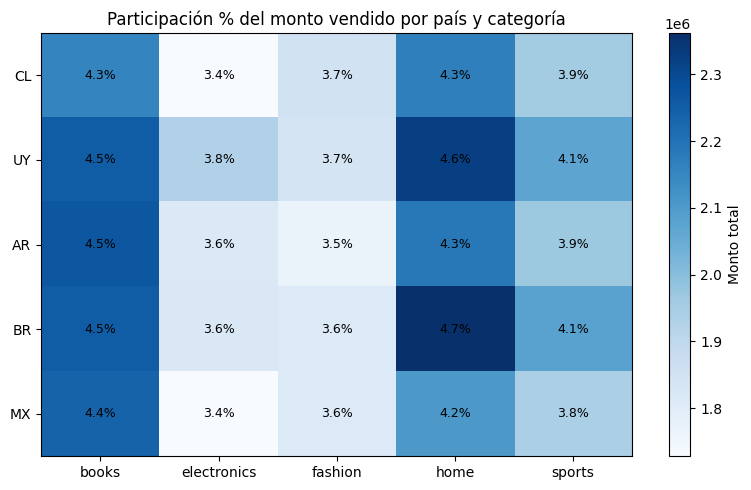

In [0]:
pivot = pivot.astype(float)
total_general = pivot.values.sum()

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(pivot.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
ax.set_title("Participación % del monto vendido por país y categoría")
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        pct = pivot.values[i, j] / total_general * 100
        ax.text(j, i, f"{pct:.1f}%", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, label="Monto total")
fig.tight_layout()
plt.show()

La combinación líder es Brasil (BR) y home, con 4.7% del monto total — pero está muy cerca de otras combinaciones (UY/home 4.6%, AR/books y BR/books 4.5%, UY/books 4.5%), así que no hay un outlier dominante, es una distribución bastante pareja entre los top combos.

## Consigna 4 — Calidad del pipeline

**Pregunta:** ¿Qué proporción de cada lote fue aceptada y rechazada? ¿El lote nuevo presenta una calidad diferente del lote inicial?

Compará lotes usando proporciones además de cantidades absolutas. Señalá cualquier limitación de comparar lotes de tamaños distintos. Fuente sugerida: `gold_batch_summary`.

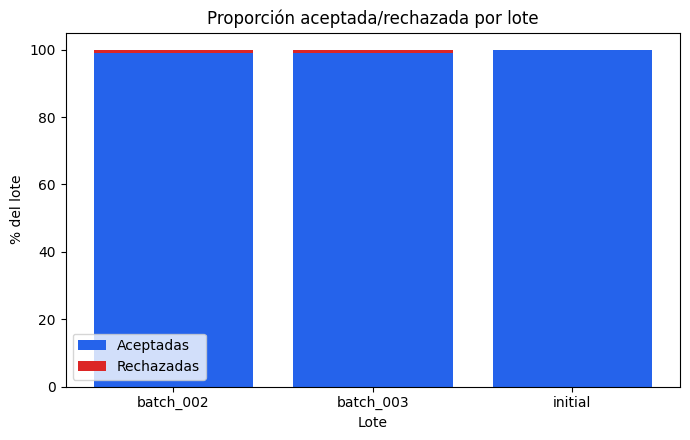

In [0]:
batch_data = (spark.table(batch)
    .withColumn("total", F.col("accepted_transactions") + F.col("rejected_transactions"))
    .withColumn("accepted_pct", F.col("accepted_transactions") / F.col("total") * 100)
    .withColumn("rejected_pct", F.col("rejected_transactions") / F.col("total") * 100)
    .orderBy("source_batch_id"))

plot_data = batch_data.toPandas()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(plot_data["source_batch_id"], plot_data["accepted_pct"], label="Aceptadas", color="#2563eb")
ax.bar(plot_data["source_batch_id"], plot_data["rejected_pct"], bottom=plot_data["accepted_pct"], label="Rechazadas", color="#dc2626")
ax.set_ylabel("% del lote")
ax.set_xlabel("Lote")
ax.set_title("Proporción aceptada/rechazada por lote")
ax.legend()
fig.tight_layout()

Cada lote tiene aceptación cercana al 100% (initial ≈99.90%, batch_002/batch_003 ≈99.01%). Sí, el lote nuevo presenta calidad distinta: rechaza proporcionalmente casi 10 veces más que initial (≈0.99% contra ≈0.10%), aunque en cantidad absoluta tenga muchos menos rechazos.

## Criterios de entrega

Para cada consigna entregá: (1) la transformación de datos, (2) un gráfico, y (3) una conclusión de dos o tres oraciones que responda explícitamente la pregunta.

Cada gráfico debe tener título informativo, ejes y unidades legibles, categorías ordenadas cuando corresponda y una elección de color que no sea la única forma de comunicar el significado. No conviertas una tabla Silver completa a Pandas: agregá primero con Spark y convertí sólo el resultado pequeño.